# Task 3 -- Feature analysis

Four views of what the text features measure and how the models use them.
Everything here is read from CSVs written by `src/analysis.py`, which needs the
gitignored embedding cache; this notebook does not.

    python src/ablation.py
    python src/analysis.py

1. **Embedding map** -- SBERT headlines in the plane of their first two
   principal components, with the seven channel axes drawn as arrows.
2. **SHAP + headline retrieval** -- which features the C5 model leans on, and
   the headlines behind its largest text-driven calls.
3. **Event check** -- do the channels react to known events? No returns used.
4. **Error table** -- the days where C5 and Model A disagree.

The plan named UMAP and LightGBM. A linear map is used because only a linear
projection turns an axis into an arrow, and SHAP comes from XGBoost's built-in
exact TreeSHAP, because the C5 models are XGBoost.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config
import viz

viz.apply_style()
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 60)
print("project root:", ROOT)

project root: C:\Users\lenovo\Documents\codng\nlp-project


In [2]:
from anchors import CHANNELS

R = config.RESULTS_DIR
pts = pd.read_csv(config.ANALYSIS_MAP_CSV, parse_dates=["date"])
arrows = pd.read_csv(config.ANALYSIS_MAP_AXES_CSV)
imp = pd.read_csv(config.ANALYSIS_SHAP_CSV)
shifts = pd.read_csv(config.ANALYSIS_SHIFTS_CSV, parse_dates=["date"])
heads = pd.read_csv(config.ANALYSIS_SHIFT_HEADLINES_CSV, parse_dates=["date"])
events = pd.read_csv(config.ANALYSIS_EVENTS_CSV)
errors = pd.read_csv(config.ANALYSIS_ERRORS_CSV, parse_dates=["date"])
pd.set_option("display.max_colwidth", 110)

## 1. Embedding map

Each dot is a headline; orange dots come from sessions with a large move. Each
arrow starts at its channel's topic vector and points toward the USD/IDR-up
pole. Arrows are scaled up by a common factor so they are visible; the table
below gives each axis's true share in this plane.

findfont: Failed to find font weight 600 for DejaVu Sans, now using 700.


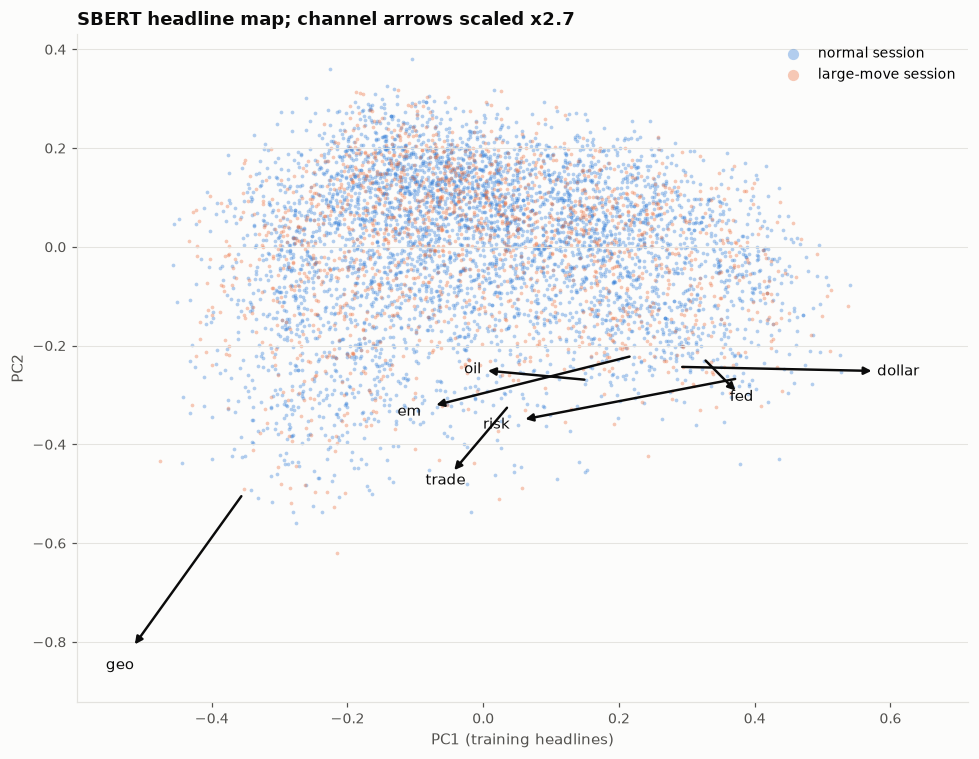

In [3]:
fig, ax = plt.subplots(figsize=(9, 7))
for flag, color, label in [(0, viz.BLUE, "normal session"), (1, viz.ORANGE, "large-move session")]:
    s = pts[pts.large_move == flag]
    ax.scatter(s.x, s.y, s=6, color=color, alpha=0.35, linewidths=0, label=label)
scale = 0.35 / arrows.in_plane_share.max()
for r in arrows.itertuples():
    ax.annotate("", xy=(r.x0 + scale * r.dx, r.y0 + scale * r.dy), xytext=(r.x0, r.y0),
                arrowprops=dict(arrowstyle="-|>", color=viz.TEXT_PRIMARY, lw=1.6))
    ax.text(r.x0 + scale * r.dx * 1.12, r.y0 + scale * r.dy * 1.12, r.channel,
            fontsize=10, color=viz.TEXT_PRIMARY, ha="center", va="center")
ax.set_xlabel("PC1 (training headlines)")
ax.set_ylabel("PC2")
ax.set_title(f"SBERT headline map; channel arrows scaled x{scale:.1f}")
# Keep every arrow tip and label inside the frame.
tips_x = arrows.x0 + scale * arrows.dx * 1.2
tips_y = arrows.y0 + scale * arrows.dy * 1.2
ax.set_xlim(min(pts.x.min(), tips_x.min()) - 0.05, max(pts.x.max(), tips_x.max()) + 0.08)
ax.set_ylim(min(pts.y.min(), tips_y.min()) - 0.05, max(pts.y.max(), tips_y.max()) + 0.05)
ax.legend(loc="upper right", markerscale=3)
plt.tight_layout()
plt.show()

In [4]:
print(f"large-move share among mapped headlines: {pts.large_move.mean():.3f}")
arrows[["channel", "in_plane_share"]].sort_values("in_plane_share", ascending=False).round(3)

large-move share among mapped headlines: 0.274


,channel,in_plane_share
3,geo,0.131
1,risk,0.123
5,em,0.116
0,dollar,0.108
6,trade,0.060
4,oil,0.057
2,fed,0.032


## 2. SHAP: what the C5 models lean on

Mean |SHAP| over the test block, in log-odds. Blue bars are rate features,
orange bars are text features (channel scores, novelty).

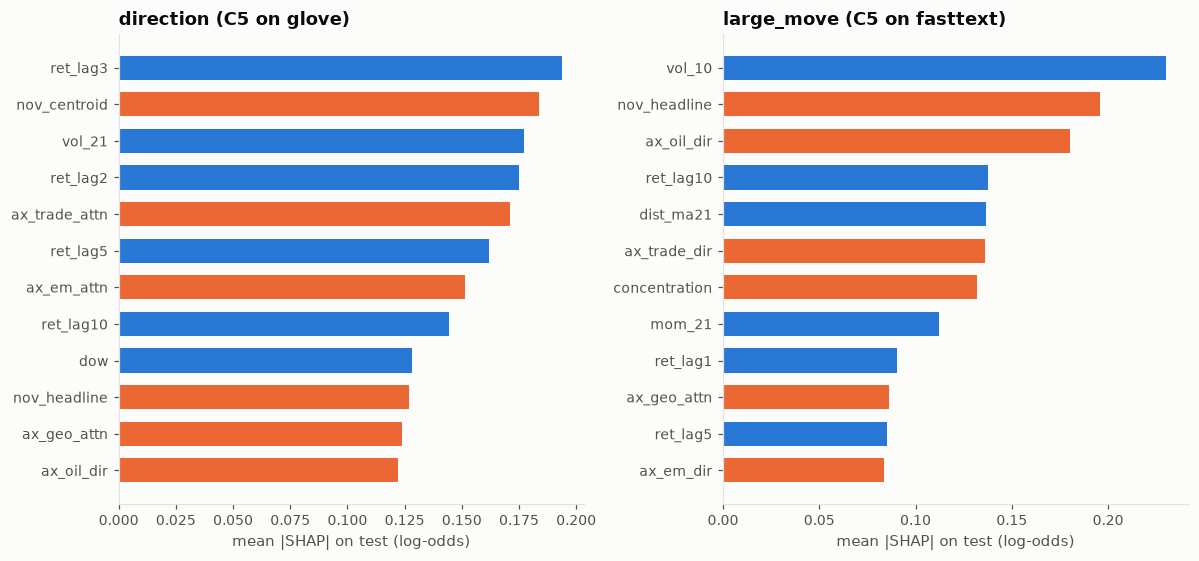

group,channel attention,channel direction,novelty,rates
target,,,,
direction,0.229,0.177,0.112,0.482
large_move,0.164,0.227,0.158,0.452


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, (target, t) in zip(axes, imp.groupby("target", sort=False)):
    t = t.sort_values("mean_abs_shap").tail(12)
    colors = [viz.COLOR_RATE if g == "rates" else viz.COLOR_NEWS for g in t.group]
    ax.barh(t.feature, t.mean_abs_shap, color=colors, height=0.66)
    ax.set_title(f"{target} (C5 on {t.encoder.iloc[0]})")
    ax.set_xlabel("mean |SHAP| on test (log-odds)")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

share = imp.groupby(["target", "group"]).mean_abs_shap.sum()
(share / share.groupby(level=0).transform("sum")).unstack().round(3)

### 2.1 The largest text-driven calls, and the headlines behind them

`text_shift` is the summed SHAP of all text features on that day: how far the
news moved the model's log-odds. `channel` is the axis feature with the
largest |SHAP|. Below each table: the headlines that channel's top-k pooling
actually used that day.

In [6]:
cols = ["date", "actual", "pred", "prob", "text_shift", "rate_shift", "channel", "top_axis_shap"]
shifts[shifts.target == "direction"][cols].round(3).reset_index(drop=True)

,date,actual,pred,prob,text_shift,rate_shift,channel,top_axis_shap
0,2026-02-24,1,1,0.922,1.616,0.638,geo,0.657
1,2026-03-12,1,1,0.913,1.570,0.569,geo,0.439
2,2026-06-18,1,1,0.934,1.496,0.941,oil,0.232
3,2026-02-12,1,1,0.875,1.303,0.426,geo,0.683
4,2026-08-14,0,1,0.837,1.251,0.175,trade,0.357
5,2026-08-10,0,1,0.951,1.245,1.507,oil,0.373
6,2026-04-20,0,0,0.299,-1.229,0.164,risk,-0.248
7,2026-07-24,1,1,0.949,1.223,1.497,geo,0.723
8,2026-08-07,0,0,0.277,-1.213,0.044,trade,-0.447
9,2026-07-15,0,1,0.819,1.181,0.119,geo,0.380


In [7]:
(heads[(heads.target == "direction") & (heads["rank"] <= 3)]
 [["date", "channel", "rank", "title", "relevance", "direction"]].round(3).reset_index(drop=True))

,date,channel,rank,title,relevance,direction
0,2026-02-24,geo,1,"Disinformation was 'central accelerant' in Leicester Hindu-Muslim clashes, inquiry finds UK news",0.204,0.246
1,2026-02-24,geo,2,"Putin Has Started World War III, Zelensky Says",0.097,-0.018
2,2026-02-24,geo,3,Spain to declassify documents on failed 1981 coup attempt,0.088,-0.060
3,2026-03-12,geo,1,"Germany, others partially release oil reserves amid Iran war",0.200,-0.005
4,2026-03-12,geo,2,Pennsylvania lawmaker to propose temporarily suspending gas taxes amid rising fuel prices,0.177,-0.001
5,2026-03-12,geo,3,Ukraine says it has hit Russian 'missile component' plant,0.121,0.202
6,2026-06-18,oil,1,"KHNP picks Yeongdeok, Gijang for new nuclear projects",0.095,0.054
7,2026-06-18,oil,2,G7 demands Lebanon ceasefire as leaders back US-Iran deal,0.054,0.102
8,2026-06-18,oil,3,Comptroller finds public service is improving but call centers are falling short,0.030,-0.031
9,2026-02-12,geo,1,"Iran's revolution anniversary marred by protests, nuclear tensions",0.514,0.162


In [8]:
shifts[shifts.target == "large_move"][cols].round(3).reset_index(drop=True)

,date,actual,pred,prob,text_shift,rate_shift,channel,top_axis_shap
0,2026-03-17,0,1,0.724,1.466,-0.595,oil,0.507
1,2026-04-13,0,1,0.776,1.206,-0.056,oil,0.407
2,2026-03-25,1,1,0.642,1.194,-0.702,geo,0.413
3,2025-12-10,0,0,0.089,-1.050,-1.370,trade,-0.120
4,2026-03-02,1,1,0.618,1.023,-0.631,geo,0.417
5,2026-04-23,1,1,0.706,0.999,-0.215,geo,0.324
6,2026-03-31,0,1,0.728,0.993,-0.099,oil,0.511
7,2026-01-12,0,1,0.517,0.985,-1.009,oil,0.437
8,2026-07-23,0,1,0.811,0.981,0.385,oil,0.473
9,2026-04-09,1,1,0.725,0.976,-0.098,oil,0.397


In [9]:
(heads[(heads.target == "large_move") & (heads["rank"] <= 3)]
 [["date", "channel", "rank", "title", "relevance", "direction"]].round(3).reset_index(drop=True))

,date,channel,rank,title,relevance,direction
0,2026-03-17,oil,1,Oil prices rise as Trump presses allies to secure the Strait of Hormuz,0.523,-0.034
1,2026-03-17,oil,2,"War on Iran Can fuel rationing, remote work, short sleeves ease oil woes?",0.466,0.028
2,2026-03-17,oil,3,Driving the future Will the conflict in the Middle East speed up the transition to electric trucks?,0.310,0.284
3,2026-04-13,oil,1,Supply restoration could take 10 days - Fuels for Ireland,0.341,0.306
4,2026-04-13,oil,2,"Top high-yield savings rates April 10, 2026 Up to 5.00% APY",0.289,-0.141
5,2026-04-13,oil,3,China to resume flights to Taiwan in bid to ease tensions,0.284,-0.038
6,2026-03-25,geo,1,Strait of Hormuz tensions flare as Iran tightens grip over shipping traffic,0.650,0.357
7,2026-03-25,geo,2,Lebanon Rebukes Iran as Israel Strikes on Hezbollah Escalate,0.558,0.259
8,2026-03-25,geo,3,Cuba readies for first Russian oil shipment of the year as energy crisis deepens,0.554,0.211
9,2025-12-10,trade,1,"S P, Nasdaq, Dow futures drift ahead of JOLTS report",0.153,0.069


## 3. Event face-validity check

Attention of the risk, geo and trade channels (SBERT), as a z-score against the
training distribution, around three events. Each event has one channel that
should react: risk for SVB, geo for 7 October, trade for the April 2025
tariffs. News is aligned to the session after it is published, so the reaction
starts after the dashed line.

findfont: Failed to find font weight 600 for DejaVu Sans, now using 700.


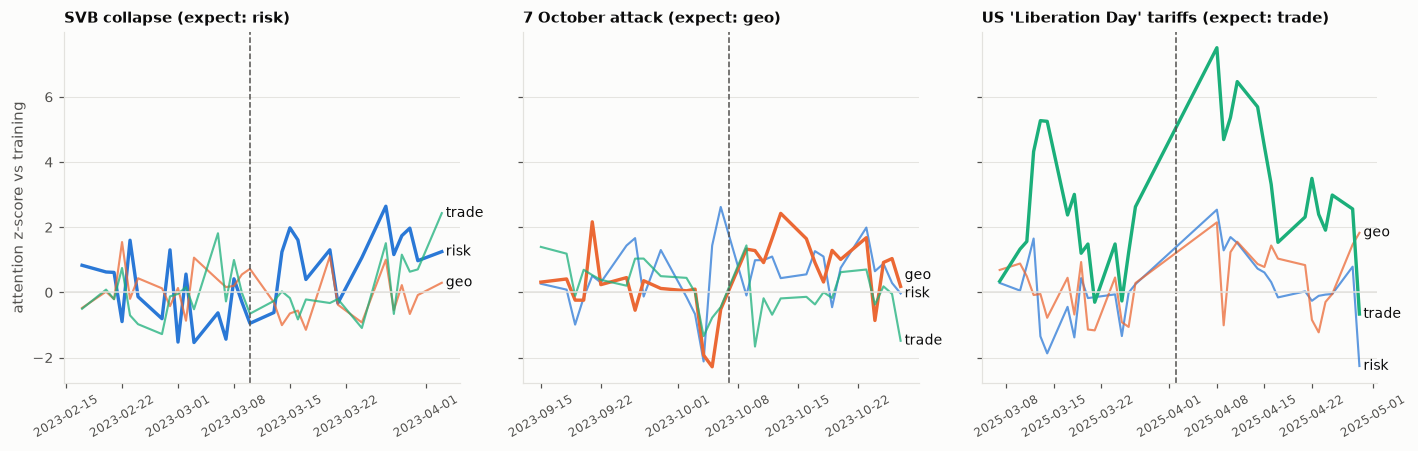

In [10]:
tf = pd.read_csv(config.TEXT_FEATURES_DIR / "sbert.csv", parse_dates=["date"]).sort_values("date")
train = tf[tf.date <= pd.Timestamp(config.TRAIN_END)]
show = {"risk": viz.BLUE, "geo": viz.ORANGE, "trade": viz.AQUA}

fig, axes = plt.subplots(1, len(config.ANALYSIS_EVENTS), figsize=(13, 4.2), sharey=True)
for ax, (name, day, expected) in zip(axes, config.ANALYSIS_EVENTS):
    d = pd.Timestamp(day)
    pos = tf.date.searchsorted(d)
    w = tf.iloc[max(0, pos - 15): pos + 15]
    ends = {}
    for ch, color in show.items():
        col = f"ax_{ch}_attn"
        z = (w[col] - train[col].mean()) / train[col].std()
        ax.plot(w.date, z, color=color, lw=2.2 if ch == expected else 1.4,
                alpha=1 if ch == expected else 0.75)
        ends[ch] = z.iloc[-1]
    # Direct labels at the line ends, nudged apart so they never overlap.
    placed = []
    for ch, y in sorted(ends.items(), key=lambda kv: kv[1]):
        y = max([y] + [p + 0.55 for p in placed[-1:]])
        placed.append(y)
        ax.text(w.date.iloc[-1], y, f" {ch}", color=viz.TEXT_PRIMARY, fontsize=9, va="center")
    ax.axvline(d, color=viz.TEXT_SECONDARY, ls="--", lw=1)
    ax.axhline(0, color=viz.GRID, lw=1)
    ax.set_title(f"{name} (expect: {expected})", fontsize=10)
    ax.tick_params(axis="x", labelrotation=30, labelsize=8)
axes[0].set_ylabel("attention z-score vs training")
plt.tight_layout()
plt.show()

Rank of the expected channel's attention spike among all seven channels (1 =
the biggest spike), and its size, for every encoder:

In [11]:
exp = events[events.channel == events.expected]
pd.concat({"rank": exp.pivot(index="event", columns="encoder", values="attn_rank"),
           "z": exp.pivot(index="event", columns="encoder", values="attn_z_max").round(2)}, axis=1)

rank                            z                    
encoder                     fasttext finbert glove sbert fasttext finbert glove sbert
event                                                                                
7 October attack                   4       6     4     3     1.86    1.09  1.70  2.43
SVB collapse                       4       1     1     2     1.51    1.71  1.98  1.98
US 'Liberation Day' tariffs        1       1     1     1     5.10    3.17  7.06  7.51

In [12]:
# All seven channels for SBERT: attention spike and mean direction (+ = USD/IDR up).
(events[events.encoder == "sbert"]
 .sort_values(["event", "attn_rank"])
 [["event", "window", "channel", "attn_z_max", "dir_z_mean", "attn_rank"]]
 .round(2).reset_index(drop=True))

,event,window,channel,attn_z_max,dir_z_mean,attn_rank
0,7 October attack,2023-10-09..2023-10-13,em,3.71,-0.05,1
1,7 October attack,2023-10-09..2023-10-13,oil,2.52,-0.26,2
2,7 October attack,2023-10-09..2023-10-13,geo,2.43,0.65,3
3,7 October attack,2023-10-09..2023-10-13,fed,1.58,0.06,4
4,7 October attack,2023-10-09..2023-10-13,trade,1.44,0.15,5
5,7 October attack,2023-10-09..2023-10-13,risk,1.10,0.26,6
6,7 October attack,2023-10-09..2023-10-13,dollar,0.75,-0.16,7
7,SVB collapse,2023-03-13..2023-03-17,dollar,2.23,-0.98,1
8,SVB collapse,2023-03-13..2023-03-17,risk,1.98,1.55,2
9,SVB collapse,2023-03-13..2023-03-17,fed,1.93,-0.49,3


## 4. Error table: where do C5 and Model A disagree?

Test days split by which model was right. For each group: how many days, the
mean absolute return, the news volume and the novelty of the day's news.

In [13]:
(errors.groupby(["target", "group"])
 .agg(days=("date", "size"), abs_return=("abs_return", "mean"),
      n_articles=("n_articles", "mean"), nov_centroid=("nov_centroid", "mean"))
 .round(4))

days  abs_return  n_articles  nov_centroid
target     group                                                        
direction  A right, C5 wrong    28      0.0022     33.0000        0.8713
           C5 right, A wrong    19      0.0019     29.4211        0.8431
           both right           69      0.0024     34.3478        0.8279
           both wrong           60      0.0022     32.2333        0.8336
large_move A right, C5 wrong    32      0.0019     35.2500        0.6752
           C5 right, A wrong    20      0.0036     39.6500        0.8223
           both right           81      0.0019     28.8272        0.7973
           both wrong           43      0.0025     35.6047        0.7725

In [14]:
# Days where the news model was right and the rates model wrong, with the
# day's most FX-relevant headlines.
(errors[errors.group == "C5 right, A wrong"]
 [["target", "date", "actual", "abs_return", "top_headlines"]]
 .sort_values(["target", "abs_return"], ascending=[True, False])
 .groupby("target").head(6).round(4).reset_index(drop=True))

,target,date,actual,abs_return,top_headlines
0,direction,2026-03-10,0,0.0056,Short sales on the TSX What bearish investors are betting against | Earnings Breakdown FuelCell Energy Q1 ...
1,direction,2026-08-05,0,0.0056,Deutsche Bank Wicksell's 'natural rate of interest' explains why investors keep funding US debt | Latest T...
2,direction,2026-04-27,0,0.0030,China opens government bond futures to select foreign investors in reform push | Lebanon is a house divide...
3,direction,2026-06-23,1,0.0027,Annual wholesale energy fuel prices up 37% in May | Linked Finance surpasses 400m in lending to SMEs | Van...
4,direction,2026-08-04,1,0.0026,Rupee ends flat as robust importer hedging blunts oil price relief | Escorts Kubota posts rise in adjusted...
5,direction,2026-02-20,0,0.0024,Iran-Trump live US military 'to strike within days' after White House warns Tehran to make a deal | Turkis...
6,large_move,2026-05-18,1,0.0097,Dollar Rally Gains Steam As Traders Scale Back Fed Rate Cut Bets These ETFs Are Climbing - Invesco DB USD ...
7,large_move,2026-06-10,1,0.0094,"Stocks recover from sell-off, but even bulls warn of more volatility | Russian attacks kill 5 in Ukraine a..."
8,large_move,2026-06-29,1,0.0059,FDA to discuss easing restrictions on peptides despite safety concerns | 'Memory supply crisis' Wall Stree...
9,large_move,2026-07-17,1,0.0054,What's at stake for Europe's carbon market blueprint? | Ukraine lawmakers approve Koretskyi as new PM amid...


In [15]:
(errors[errors.group == "A right, C5 wrong"]
 [["target", "date", "actual", "abs_return", "top_headlines"]]
 .sort_values(["target", "abs_return"], ascending=[True, False])
 .groupby("target").head(6).round(4).reset_index(drop=True))

,target,date,actual,abs_return,top_headlines
0,direction,2026-06-04,1,0.0060,"Rupee dented by oil price jump, equity weakness likely RBI intervention caps losses | Despite inventory bu..."
1,direction,2026-05-12,1,0.0057,"Trump says peace proposal response 'unacceptable,' raising fears Hormuz will stay closed | Norway puts UN ..."
2,direction,2026-04-29,1,0.0046,Iran war begins to hit China's economy as costs surge | Israel's Independence Day reflections amid war and...
3,direction,2026-02-23,0,0.0040,Trump imposes new 10% tariffs following Supreme Court ruling | DR Congo Residents of Uvira call for urgent...
4,direction,2026-01-23,0,0.0038,"Pound Sterling trades higher ahead of UK Retail Sales, flash PMI data | EUR USD pares losses as the focus ..."
5,direction,2026-07-01,1,0.0035,"Hormuz disruption may have lasting impact on vulnerable economies, UN trade agency says | Islamic coalitio..."
6,large_move,2026-06-15,1,0.0113,"Trump faces G7 after year of trade wrath, diplomatic bluster - Economy | Israeli military strikes Beirut s..."
7,large_move,2026-08-28,0,0.0033,Russia threatens UK military targets while Kremlin denies intent to attack NATO | Russia confirms Moscow m...
8,large_move,2026-03-16,0,0.0033,Fed expected to hold rates steady as Iran war roils outlook - Economy | ASEAN calls for energy and food se...
9,large_move,2026-03-09,0,0.0032,"US Stocks Outperform Global Peers in Week of Energy Price Chaos, Iran War | Iran President's Apology Spark..."


## 5. Findings

1. **The channels pass the event check for financial shocks, and only partly
   for war.** The April 2025 tariffs produce the largest trade-channel spike in
   every encoder (z = 3.2 to 7.5, rank 1 of 7). SVB moves the four financial
   channels (dollar, risk, fed, EM) and leaves geo at its lowest; risk-off and
   EM-outflow directions both point USD-up, as theory says. After 7 October
   the geo channel does spike (SBERT z = 2.4) and points toward escalation, but
   EM and oil spike more. Geo ranks 3rd to 6th, so the geo axis is the weakest
   of the three.

2. **Text features carry about half of each C5 model's attributions.** Channel
   scores and novelty account for 52% (direction) and 55% (large move) of mean
   |SHAP| on test. The models use the text heavily; the ablation shows this
   does not turn into a reliable gain.

3. **Retrieval exposes the encoder difference.** For large moves (FastText),
   the headlines behind the biggest text-driven calls are on-topic: Strait of
   Hormuz, US–Israel strikes on Iran, oil supply. For direction (GloVe), the
   top-k pooling often picks off-topic headlines ("Bakery tourism is booming"
   counted as trade news). GloVe's topic relevance is too loose to trust.

4. **News helps on novel, big-move days.** On large moves, the 20 days where C5
   was right and A wrong have nearly twice the absolute return (0.36% vs
   0.19%) and much more novel news (nov_centroid 0.82 vs 0.68) than the days
   where only A was right. Direction shows no such pattern.

5. **The map is weak evidence.** The first two components explain 6.5% of
   variance, and at most 13% of any channel axis lies in that plane. The
   channel axes run mostly orthogonal to the corpus's main topic directions.
   This is expected (they contrast minimal pairs within a topic), but it means
   the 2-D picture shows little of what the axes measure.